In [1]:
!pip install -Uqq fastbook
!pip install torch
import fastbook
fastbook.setup_book()
import torch

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 16.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 6.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.1/194.1 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 11.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 18.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 53.2 MB/s eta 0:00:00
Mounted at /content/gdrive


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from fastai.imports import *
from fastai.torch_core import *
from fastai.learner import *

@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.stack(self.values)
    names = self.metric_names[1:-1]
    n = len(names) - 1
    if nrows is None and ncols is None:
        nrows = int(math.sqrt(n))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None: nrows = int(np.ceil(n / ncols))
    elif ncols is None: ncols = int(np.ceil(n / nrows))
    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = [ax if i < n else ax.set_axis_off() for i, ax in enumerate(axs.flatten())][:n]
    for i, (name, ax) in enumerate(zip(names, [axs[0]] + axs)):
        ax.plot(metrics[:, i], color='#1f77b4' if i == 0 else '#ff7f0e', label='valid' if i > 0 else 'train')
        ax.set_title(name if i > 1 else 'losses')
        ax.legend(loc='best')
    plt.show()


In [4]:
from fastbook import *

In [5]:
from fastai.vision.all import *
path = Path('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset')

In [6]:
import torch

In [7]:
train_fnames = get_image_files(path/"Train")

In [8]:
augs = [RandomResizedCropGPU(size=112, min_scale=0.75), Rotate(), Zoom()]
dblock = DataBlock(blocks=(ImageBlock(cls=PILImage), CategoryBlock),
                   splitter=RandomSplitter(valid_pct=0.2, seed=23),
                   get_y=parent_label,
                   item_tfms=Resize(224, method="squish"),
                   batch_tfms=augs,
                   )

dls = dblock.dataloaders(train_fnames)


TypeError: 'NoneType' object is not iterable

In [ ]:
# print number of classes and length of train and valid datasets
dls.c, len(dls.train_ds), len(dls.valid_ds)

NameError: name 'dls' is not defined

In [ ]:
dls.vocab

['Cyst', 'Kidney_stone', 'Normal']

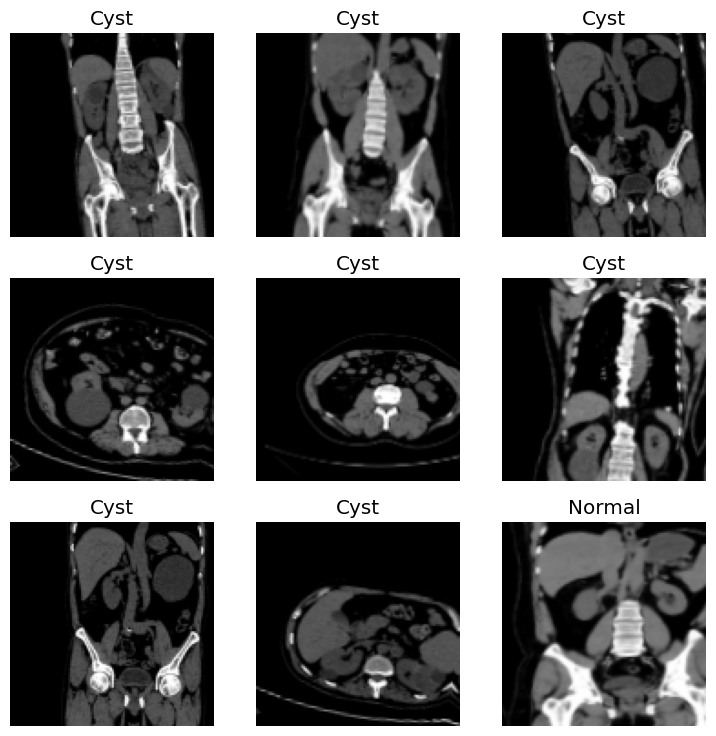

In [ ]:
dls.show_batch()

In [ ]:
model = nn.Sequential(create_body(xresnet50(), pretrained=False),create_head(nf=2048, n_out=3))
learn = Learner(dls, model, loss_func=CrossEntropyLossFlat(), metrics=accuracy)



In [ ]:
learn.fit_one_cycle(150,1e-2)
learn.recorder.plot_metrics()

In [ ]:
# Save model state_dict
torch.save(learn.model.state_dict(), path/'FinalTrained150-96.pth')


In [ ]:
learn.recorder.plot_loss(skip_start=0, with_valid=True)

In [ ]:
#test_items = get_image_files(path/"Test")
all_files= get_image_files(path)

# Evaluating model performance using the unseen test set

---



In [ ]:

augs = [RandomResizedCropGPU(size=112, min_scale=0.75), Rotate(), Zoom()]
dblock = DataBlock(blocks=(ImageBlock(cls=PILImage), CategoryBlock),
                   splitter=GrandparentSplitter(train_name='Train', valid_name='Test'),
                   get_y=parent_label,
                   item_tfms=Resize(224, method="squish"),
                   batch_tfms=augs,
                   )

dls_test = dblock.dataloaders(all_files)



In [ ]:
print("Number of examples in testing:", len(dls_test.valid_ds))

Number of examples in testing: 956


In [ ]:
model = nn.Sequential(create_body(xresnet50(), pretrained=True),create_head(nf=2048, n_out=3))

In [ ]:
learn1 = learn1 = Learner(dls_test, model, loss_func=CrossEntropyLossFlat(), metrics=accuracy).load('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/FinalTrained150-96')
learn1.load('/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/FinalTrained150-96')


/usr/local/lib/python3.10/dist-packages/fastai/learner.py:59: UserWarning: Saved file doesn't contain an optimizer state.
  elif with_opt: warn("Saved file doesn't contain an optimizer state.")


In [ ]:
#Load the image which you want to test
img = "/content/gdrive/MyDrive/Kidney_stone_detection-Final Year/Dataset/Test/Kidney_stone/1.3.46.670589.33.1.63714250724669209800001.5121096612764671735.png"
#Predict the image
probs = learn1.predict(img)
#print the prediction
print(probs)

('Kidney_stone', tensor(1), tensor([3.6820e-10, 1.0000e+00, 1.1265e-06]))


/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()
/usr/lib/python3.10/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


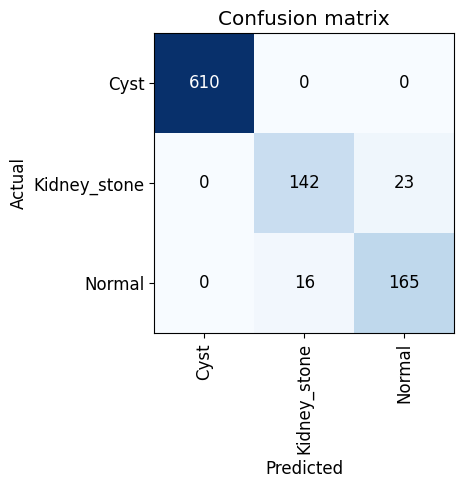

In [ ]:
interp = ClassificationInterpretation.from_learner(learn1)
interp.plot_confusion_matrix()


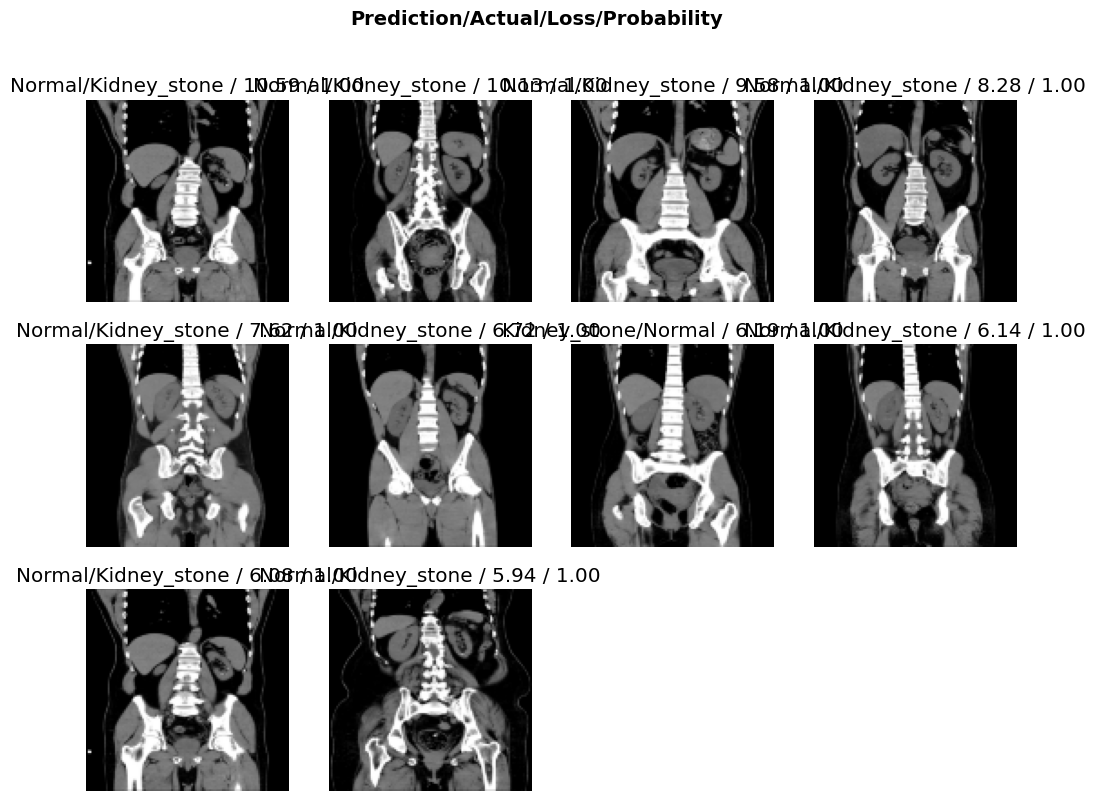

In [ ]:
#Top 10 losses occured during validation of our test dataset
#for whole testing dataset
#interp.plot_top_losses(len(dls_test.valid_ds))
interp.plot_top_losses(10)


Top Losses: TensorBase([1.0588e+01, 1.0125e+01, 9.5779e+00, 8.2793e+00, 7.6161e+00, 6.7182e+00, 6.1910e+00, 6.1364e+00, 6.0761e+00, 5.9425e+00, 5.2726e+00, 5.0827e+00, 4.5942e+00, 4.1687e+00, 3.8178e+00,
            3.5311e+00, 3.3518e+00, 3.3382e+00, 3.3242e+00, 2.7535e+00, 2.6884e+00, 2.5986e+00, 2.3099e+00, 2.2986e+00, 1.9989e+00, 1.9899e+00, 1.8693e+00, 1.7119e+00, 1.5411e+00, 1.5083e+00,
            1.4612e+00, 1.4049e+00, 1.2185e+00, 1.1992e+00, 1.1474e+00, 9.6507e-01, 9.6184e-01, 9.0419e-01, 7.6267e-01, 6.4624e-01, 6.0644e-01, 5.9778e-01, 5.6081e-01, 5.5743e-01, 5.2354e-01,
            4.9083e-01, 4.8608e-01, 4.8054e-01, 4.7316e-01, 4.6735e-01, 4.1083e-01, 4.0409e-01, 3.8717e-01, 3.7913e-01, 3.7718e-01, 3.3332e-01, 3.2948e-01, 3.2015e-01, 3.1605e-01, 3.1054e-01,
            3.0552e-01, 2.8277e-01, 2.7994e-01, 2.6525e-01, 2.2589e-01, 2.1036e-01, 1.7067e-01, 1.4606e-01, 1.1952e-01, 1.1763e-01, 1.1689e-01, 1.1442e-01, 1.0912e-01, 1.0405e-01, 9.2626e-02,
            8.9414e-02, 8.14

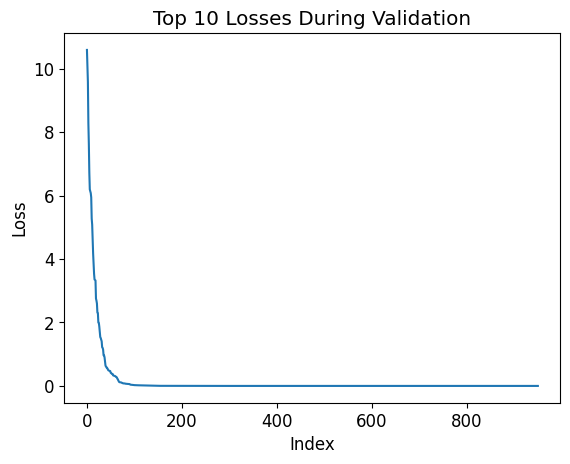

In [ ]:
top_k_losses, top_k_idxs = interp.top_losses(k=950, largest=True)  # Get top 5 highest losses
print("Top Losses:", top_k_losses)

#for whole dataset set value of k = len(dls_test.valid_ds)

import matplotlib.pyplot as plt

plt.plot(top_k_losses)  # Simple plot of top losses
plt.xlabel("Index")
plt.ylabel("Loss")
plt.title("Top 10 Losses During Validation")
plt.show()



In [ ]:
interp.print_classification_report()

              precision    recall  f1-score   support

        Cyst       1.00      1.00      1.00       610
Kidney_stone       0.90      0.86      0.88       165
      Normal       0.88      0.91      0.89       181

    accuracy                           0.96       956
   macro avg       0.93      0.92      0.92       956
weighted avg       0.96      0.96      0.96       956

